# Ипорты

In [39]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import date, timedelta
from typing import Optional

from sklearn.metrics import mean_squared_error
from catboost import CatBoostRegressor

# База по данным

In [16]:
data = pl.read_parquet('data/train.parquet')
data.shape

(30631006, 18)

In [17]:
data.columns

['event_date',
 'user_id',
 'search',
 'cat',
 'has_search_to_cart',
 'has_search_to_ord',
 'has_cat_to_cart',
 'has_cat_to_ord',
 'search_to_cart',
 'search_to_ord',
 'cat_to_cart',
 'cat_to_ord',
 'gmv_search',
 'gmv_cat',
 'to_cart',
 'to_ord',
 'gmv',
 'searches']

In [41]:
numeric_features = [
    'search',
    'cat',
    'has_search_to_cart',
    'has_search_to_ord',
    'has_cat_to_cart',
    'has_cat_to_ord',
    'search_to_cart',
    'search_to_ord',
    'cat_to_cart',
    'cat_to_ord',
    'gmv_search',
    'gmv_cat',
    'to_cart',
    'to_ord',
    'gmv',
    'searches'
]

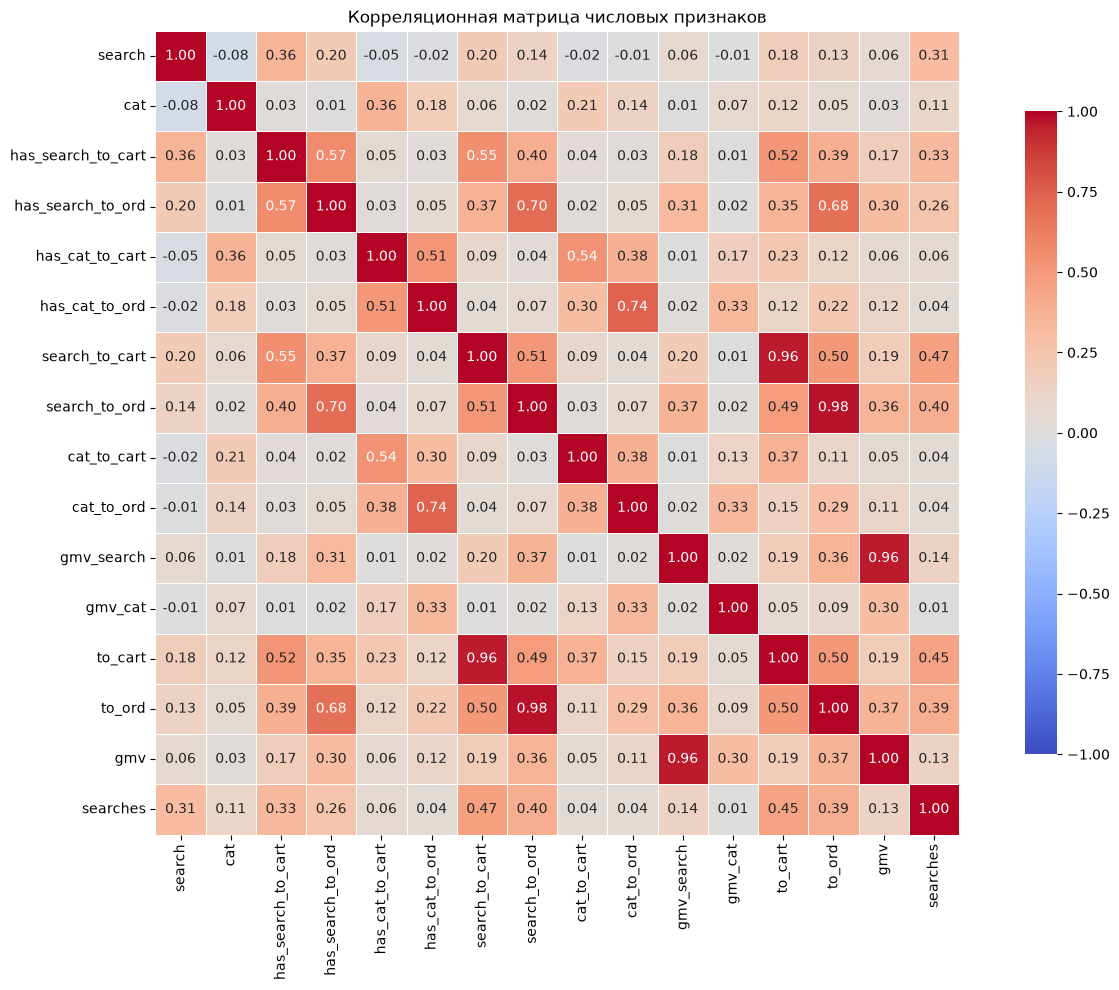

In [46]:
corr_matrix = data.select(numeric_features).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    vmin=-1, vmax=1,
    xticklabels=numeric_features,
    yticklabels=numeric_features,
)

plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

# Предобработка

In [18]:
user_features = (
    data
    .group_by('user_id')
    .agg([
        pl.len().alias('active_days'),

        pl.col('search').sum().alias('search_days'),
        pl.col('cat').sum().alias('cat_days'),

        pl.col('searches').sum().alias('searches'),

        pl.col('to_cart').sum().alias('cart_items'),
        pl.col('to_ord').sum().alias('orders'),

        pl.col('gmv').sum().alias('gmv'),

        pl.col('gmv_search').sum().alias('gmv_search'),
        pl.col('gmv_cat').sum().alias('gmv_cat'),

        pl.col('search_to_cart').sum().alias('search_to_cart'),
        pl.col('search_to_ord').sum().alias('search_to_ord'),

        pl.col('cat_to_cart').sum().alias('cat_to_cart'),
        pl.col('cat_to_ord').sum().alias('cat_to_ord'),
    ])
)

display(user_features.head())

user_id,active_days,search_days,cat_days,searches,cart_items,orders,gmv,gmv_search,gmv_cat,search_to_cart,search_to_ord,cat_to_cart,cat_to_ord
i64,u32,i64,i64,i64,i64,i64,f64,f64,f64,i64,i64,i64,i64
538478,19,8,0,19,1,0,0.0,0.0,0.0,1,0,0,0
791732,53,41,1,65,13,10,217.573018,217.573018,0.0,13,10,0,0
629976,106,68,5,142,19,13,245.650919,245.650919,0.0,18,13,1,0
733803,53,46,8,65,12,2,40.608602,40.608602,0.0,10,2,2,0
749008,118,102,12,326,99,39,1306.908172,1176.980906,129.927266,88,36,11,3


In [19]:
user_features.shape

(250000, 14)

In [20]:
user_features.describe()

statistic,user_id,active_days,search_days,cat_days,searches,cart_items,orders,gmv,gmv_search,gmv_cat,search_to_cart,search_to_ord,cat_to_cart,cat_to_ord
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",458196.34888,122.524024,98.8255,19.070536,393.833904,127.763576,32.207872,1088.406296,1008.43223,79.974066,117.922688,30.388076,9.840888,1.819796
"""std""",265437.525035,87.445046,77.560188,30.226823,549.407268,218.719647,63.536926,2303.746136,2161.97759,412.016581,200.879646,60.539873,37.12453,8.287735
"""min""",2.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",227782.0,51.0,37.0,3.0,92.0,20.0,3.0,73.760933,64.832891,0.0,18.0,3.0,0.0,0.0
"""50%""",457512.0,102.0,78.0,9.0,219.0,57.0,14.0,388.193007,351.586983,0.0,53.0,13.0,2.0,0.0
"""75%""",688452.0,178.0,143.0,22.0,488.0,148.0,38.0,1210.38622,1115.344935,35.082512,137.0,35.0,8.0,1.0
"""max""",918481.0,409.0,409.0,406.0,25723.0,16563.0,3359.0,123075.702541,122528.212438,86944.02716,12747.0,3238.0,6629.0,1462.0


 - searches_per_active_day  = поисков за день
 - orders_per_active_day    = заказов за день
 - gmv_per_active_day       = выручки за день
 - avg_order_value          = средний чек (GMV / заказы)

In [24]:
user_features = user_features.with_columns([
    (
        pl.col('searches') /
        (pl.col('active_days') + 1)
    ).alias('searches_per_active_day'),

    (
        pl.col('orders') /
        (pl.col('active_days') + 1)
    ).alias('orders_per_active_day'),

    (
        pl.col('gmv') /
        (pl.col('active_days') + 1)
    ).alias('gmv_per_active_day'),

    (
        pl.col('gmv') /
        (pl.col('orders') + 1)
    ).alias('avg_order_value'),
])

 - search_gmv_share  = сколько % выручки пришло через поиск
 - cat_gmv_share     = сколько % выручки пришло через категории

In [25]:
user_features = user_features.with_columns([
    (
        pl.col('gmv_search') /
        (pl.col('gmv') + 1)
    ).alias('search_gmv_share'),

    (
        pl.col('gmv_cat') /
        (pl.col('gmv') + 1)
    ).alias('cat_gmv_share'),
])

In [29]:
display(
    user_features.select([
        'user_id',
        'active_days',
        'searches',
        'orders',
        'gmv',
        'search_gmv_share',
        'cat_gmv_share',
        'searches_per_active_day',
        'orders_per_active_day',
        'gmv_per_active_day',
        'avg_order_value',
    ]).head(5)
)

user_id,active_days,searches,orders,gmv,search_gmv_share,cat_gmv_share,searches_per_active_day,orders_per_active_day,gmv_per_active_day,avg_order_value
i64,u32,i64,i64,f64,f64,f64,f64,f64,f64,f64
538478,19,19,0,0.0,0.0,0.0,0.95,0.0,0.0,0.0
791732,53,65,10,217.573018,0.995425,0.0,1.203704,0.185185,4.02913,19.779365
629976,106,142,13,245.650919,0.995946,0.0,1.327103,0.121495,2.295803,17.546494
733803,53,65,2,40.608602,0.975967,0.0,1.203704,0.037037,0.752011,13.536201
749008,118,326,39,1306.908172,0.899896,0.09934,2.739496,0.327731,10.982422,32.672704


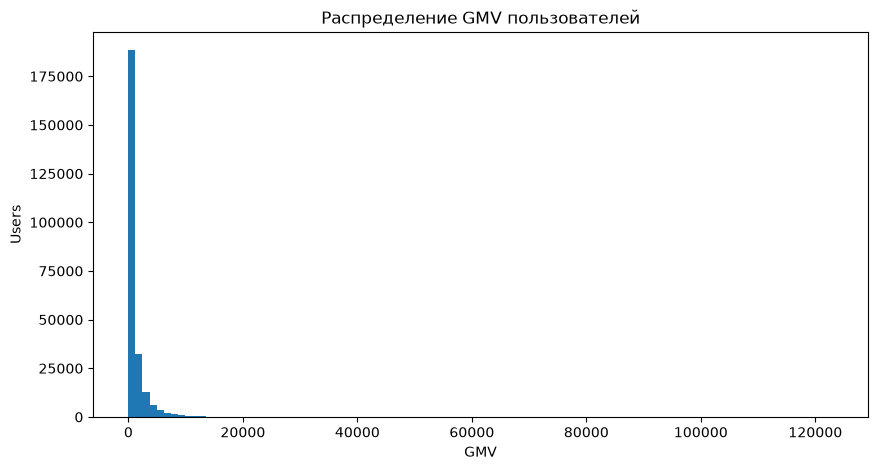

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_features['gmv'],
    bins=100
)

plt.xlabel('GMV')
plt.ylabel('Users')
plt.title('Распределение GMV пользователей')

plt.show()

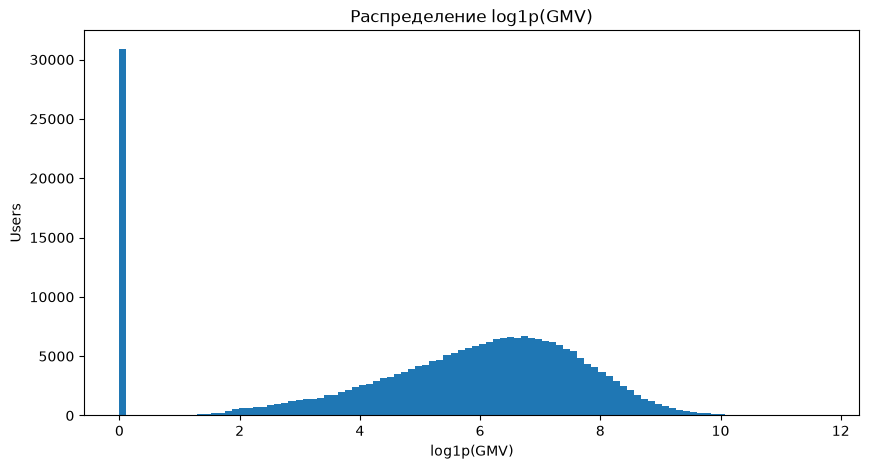

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(
    np.log1p(user_features['gmv']),
    bins=100
)

plt.xlabel('log1p(GMV)')
plt.ylabel('Users')
plt.title('Распределение log1p(GMV)')

plt.show()